In [17]:
import os

In [18]:
import numpy as np
from rdkit import Chem
from rdkit.Chem import AllChem
from rdkit.Chem.Draw import rdMolDraw2D
from rdkit.Chem.rdMolDescriptors import CalcMolFormula
from rdkit.Geometry import Point3D

def read_mol_file(filepath):
    mol = Chem.MolFromMolFile(filepath, removeHs=False)
    if mol is None:
        raise ValueError(f"无法读取mol文件: {filepath}")
    return mol

def find_aldehyde_groups(mol):
    groups = []
    for atom in mol.GetAtoms():
        if atom.GetSymbol() == 'C':
            for bond in atom.GetBonds():
                neighbor = bond.GetOtherAtom(atom)
                if neighbor.GetSymbol() == 'O' and bond.GetBondType() == Chem.BondType.DOUBLE:
                    if neighbor.GetDegree() == 1:
                        groups.append((atom.GetIdx(), neighbor.GetIdx()))
                        break
    return groups

def find_amine_nitrogens(mol):
    nitrogens = []
    for atom in mol.GetAtoms():
        if atom.GetSymbol() == 'N':
            h_count = atom.GetTotalNumHs()
            if h_count >= 2 and atom.GetDegree() == 1:
                nitrogens.append(atom.GetIdx())
    return nitrogens

def draw_molecule(mol, filepath, size=(1200, 900)):
    drawer = rdMolDraw2D.MolDraw2DCairo(size[0], size[1])
    drawer.drawOptions().addAtomIndices = False
    drawer.DrawMolecule(mol)
    drawer.FinishDrawing()
    with open(filepath, 'wb') as f:
        f.write(drawer.GetDrawingText())
    print(f"  结构图已保存: {filepath}")

def rotate_vec_2d(vec, angle_deg):
    angle = np.radians(angle_deg)
    cos_a, sin_a = np.cos(angle), np.sin(angle)
    return np.array([cos_a * vec[0] - sin_a * vec[1], sin_a * vec[0] + cos_a * vec[1]])

def mirror_point_along_axis(point, axis_origin, axis_dir):
    p_rel = point - axis_origin
    d = axis_dir / np.linalg.norm(axis_dir)
    p_mirror = 2 * np.dot(p_rel, d) * d - p_rel
    return p_mirror + axis_origin

def mirror_vec_along_axis(vec, axis_dir):
    d = axis_dir / np.linalg.norm(axis_dir)
    return 2 * np.dot(vec, d) * d - vec

def get_edge_direction(conf, vertex_idx, all_vertices_idx):
    """找到与vertex_idx最近的顶点，返回边的方向"""
    vertex_pos = np.array([conf.GetAtomPosition(vertex_idx).x, conf.GetAtomPosition(vertex_idx).y])
    min_dist = float('inf')
    nearest_pos = None
    for idx in all_vertices_idx:
        if idx == vertex_idx:
            continue
        pos = np.array([conf.GetAtomPosition(idx).x, conf.GetAtomPosition(idx).y])
        dist = np.linalg.norm(pos - vertex_pos)
        if dist < min_dist:
            min_dist = dist
            nearest_pos = pos
    edge_dir = nearest_pos - vertex_pos
    return edge_dir / np.linalg.norm(edge_dir)

def calc_edge_parallelism(ald_edge_dir, ami_edge_dir_original, ami_ny_dir, nc_dir, flip):
    """计算变换后ami边与ald边的平行度"""
    current_edge = ami_edge_dir_original.copy()
    current_ny = ami_ny_dir.copy()
    
    # 如果翻转，先沿N-Y轴镜像边方向
    if flip:
        current_edge = mirror_vec_along_axis(current_edge, current_ny)
    
    # 目标N-Y方向（-120度）
    target_ny = rotate_vec_2d(nc_dir, -120)
    
    # 计算旋转角度
    rot_angle = np.arctan2(target_ny[1], target_ny[0]) - np.arctan2(current_ny[1], current_ny[0])
    
    # 旋转边方向
    cos_r, sin_r = np.cos(rot_angle), np.sin(rot_angle)
    final_edge = np.array([
        cos_r * current_edge[0] - sin_r * current_edge[1],
        sin_r * current_edge[0] + cos_r * current_edge[1]
    ])
    
    # 计算平行度
    return np.abs(np.dot(ald_edge_dir, final_edge))

def merge_with_2d_coords(ald_mol, ami_mol, flip=False):
    """合并两个分子，角度固定为-120"""
    AllChem.Compute2DCoords(ald_mol)
    AllChem.Compute2DCoords(ami_mol)
    
    ald_groups = find_aldehyde_groups(ald_mol)
    ami_nitrogens = find_amine_nitrogens(ami_mol)
    
    ald_c_idx, ald_o_idx = ald_groups[0]
    ami_n_idx = ami_nitrogens[0]
    
    ald_conf = ald_mol.GetConformer()
    ami_conf = ami_mol.GetConformer()
    
    ald_c_pos = np.array([ald_conf.GetAtomPosition(ald_c_idx).x, ald_conf.GetAtomPosition(ald_c_idx).y])
    ald_o_pos = np.array([ald_conf.GetAtomPosition(ald_o_idx).x, ald_conf.GetAtomPosition(ald_o_idx).y])
    
    ami_n_pos = np.array([ami_conf.GetAtomPosition(ami_n_idx).x, ami_conf.GetAtomPosition(ami_n_idx).y])
    ami_n_atom = ami_mol.GetAtomWithIdx(ami_n_idx)
    ami_y_idx = None
    for neighbor in ami_n_atom.GetNeighbors():
        if neighbor.GetSymbol() == 'C':
            ami_y_idx = neighbor.GetIdx()
            break
    ami_y_pos = np.array([ami_conf.GetAtomPosition(ami_y_idx).x, ami_conf.GetAtomPosition(ami_y_idx).y])
    
    # 如果翻转，沿N-Y轴镜像
    if flip:
        ny_dir = ami_y_pos - ami_n_pos
        for i in range(ami_mol.GetNumAtoms()):
            pos = ami_conf.GetAtomPosition(i)
            p = np.array([pos.x, pos.y])
            p_new = mirror_point_along_axis(p, ami_n_pos, ny_dir)
            ami_conf.SetAtomPosition(i, Point3D(p_new[0], p_new[1], 0))
        ami_y_pos = np.array([ami_conf.GetAtomPosition(ami_y_idx).x, ami_conf.GetAtomPosition(ami_y_idx).y])
    
    target_n_pos = ald_o_pos
    cn_dir = target_n_pos - ald_c_pos
    cn_dir = cn_dir / np.linalg.norm(cn_dir)
    nc_dir = -cn_dir
    target_ny_dir = rotate_vec_2d(nc_dir, -120)  # 固定-120度
    
    current_ny_dir = ami_y_pos - ami_n_pos
    current_ny_dir = current_ny_dir / np.linalg.norm(current_ny_dir)
    
    rot_angle = np.arctan2(target_ny_dir[1], target_ny_dir[0]) - np.arctan2(current_ny_dir[1], current_ny_dir[0])
    cos_r, sin_r = np.cos(rot_angle), np.sin(rot_angle)
    
    ami_n_pos = np.array([ami_conf.GetAtomPosition(ami_n_idx).x, ami_conf.GetAtomPosition(ami_n_idx).y])
    
    for i in range(ami_mol.GetNumAtoms()):
        pos = ami_conf.GetAtomPosition(i)
        p = np.array([pos.x, pos.y]) - ami_n_pos
        new_p = np.array([cos_r * p[0] - sin_r * p[1], sin_r * p[0] + cos_r * p[1]])
        new_p = new_p + ami_n_pos
        ami_conf.SetAtomPosition(i, Point3D(new_p[0], new_p[1], 0))
    
    ami_n_pos_new = np.array([ami_conf.GetAtomPosition(ami_n_idx).x, ami_conf.GetAtomPosition(ami_n_idx).y])
    translation = target_n_pos - ami_n_pos_new
    for i in range(ami_mol.GetNumAtoms()):
        pos = ami_conf.GetAtomPosition(i)
        ami_conf.SetAtomPosition(i, Point3D(pos.x + translation[0], pos.y + translation[1], 0))
    
    combined = Chem.RWMol(Chem.CombineMols(ald_mol, ami_mol))
    offset = ald_mol.GetNumAtoms()
    ami_n_combined_idx = ami_n_idx + offset
    
    combined.RemoveBond(ald_c_idx, ald_o_idx)
    combined.RemoveAtom(ald_o_idx)
    
    if ald_o_idx < ami_n_combined_idx:
        ami_n_combined_idx -= 1
    if ald_o_idx < ald_c_idx:
        ald_c_idx -= 1
    
    imine_c_idx = ald_c_idx
    imine_n_idx = ami_n_combined_idx
    
    combined.AddBond(ald_c_idx, ami_n_combined_idx, Chem.BondType.DOUBLE)
    
    while True:
        combined.UpdatePropertyCache(strict=False)
        ald_groups = find_aldehyde_groups(combined)
        if not ald_groups:
            break
        c_idx, o_idx = ald_groups[-1]
        c_atom = combined.GetAtomWithIdx(c_idx)
        ring_c_idx = None
        for neighbor in c_atom.GetNeighbors():
            if neighbor.GetSymbol() == 'C' and neighbor.GetIsAromatic():
                ring_c_idx = neighbor.GetIdx()
                break
        combined.RemoveBond(c_idx, o_idx)
        if ring_c_idx is not None:
            combined.RemoveBond(c_idx, ring_c_idx)
        atoms_to_remove = sorted([c_idx, o_idx], reverse=True)
        for rem_idx in atoms_to_remove:
            combined.RemoveAtom(rem_idx)
            if rem_idx < imine_c_idx:
                imine_c_idx -= 1
            if rem_idx < imine_n_idx:
                imine_n_idx -= 1
    
    while True:
        combined.UpdatePropertyCache(strict=False)
        ami_nitrogens = find_amine_nitrogens(combined)
        if not ami_nitrogens:
            break
        n_idx = ami_nitrogens[-1]
        n_atom = combined.GetAtomWithIdx(n_idx)
        ring_c_idx = None
        for neighbor in n_atom.GetNeighbors():
            if neighbor.GetSymbol() == 'C':
                ring_c_idx = neighbor.GetIdx()
                break
        if ring_c_idx is not None:
            combined.RemoveBond(n_idx, ring_c_idx)
        combined.RemoveAtom(n_idx)
        if n_idx < imine_c_idx:
            imine_c_idx -= 1
        if n_idx < imine_n_idx:
            imine_n_idx -= 1
    
    Chem.SanitizeMol(combined)
    return combined.GetMol(), imine_c_idx, imine_n_idx

def main(ald_path, ami_path, output_mol_path, output_png_path):
    print("=" * 70)
    print("  分子拼接程序 - 最终版（边平行度判断）")
    print("=" * 70)
    
    print("\n[读取分子文件]")
    print(f"  ald: {ald_path}")
    print(f"  ami: {ami_path}")
    
    # 获取ald和ami的边方向
    ald_mol_temp = read_mol_file(ald_path)
    ami_mol_temp = read_mol_file(ami_path)
    AllChem.Compute2DCoords(ald_mol_temp)
    AllChem.Compute2DCoords(ami_mol_temp)
    
    ald_conf = ald_mol_temp.GetConformer()
    ami_conf = ami_mol_temp.GetConformer()
    
    ald_groups = find_aldehyde_groups(ald_mol_temp)
    ami_nitrogens = find_amine_nitrogens(ami_mol_temp)
    
    ald_c_indices = [g[0] for g in ald_groups]
    ald_c_idx, ald_o_idx = ald_groups[0]
    ami_n_idx = ami_nitrogens[0]
    
    # ald边方向
    ald_edge_dir = get_edge_direction(ald_conf, ald_c_idx, ald_c_indices)
    
    # ami边方向
    ami_edge_dir = get_edge_direction(ami_conf, ami_n_idx, ami_nitrogens)
    
    # ami的N-Y方向
    ami_n_atom = ami_mol_temp.GetAtomWithIdx(ami_n_idx)
    ami_y_idx = None
    for neighbor in ami_n_atom.GetNeighbors():
        if neighbor.GetSymbol() == 'C':
            ami_y_idx = neighbor.GetIdx()
            break
    ami_n_pos = np.array([ami_conf.GetAtomPosition(ami_n_idx).x, ami_conf.GetAtomPosition(ami_n_idx).y])
    ami_y_pos = np.array([ami_conf.GetAtomPosition(ami_y_idx).x, ami_conf.GetAtomPosition(ami_y_idx).y])
    ami_ny_dir = (ami_y_pos - ami_n_pos) / np.linalg.norm(ami_y_pos - ami_n_pos)
    
    # N-C方向
    ald_c_pos = np.array([ald_conf.GetAtomPosition(ald_c_idx).x, ald_conf.GetAtomPosition(ald_c_idx).y])
    ald_o_pos = np.array([ald_conf.GetAtomPosition(ald_o_idx).x, ald_conf.GetAtomPosition(ald_o_idx).y])
    co_dir = ald_o_pos - ald_c_pos
    nc_dir = -co_dir / np.linalg.norm(co_dir)
    
    print("\n[计算两种构型的边平行度]")
    
    configs = [
        (False, '-120°, 不翻转'),
        (True, '-120°, 翻转'),
    ]
    
    best_mol = None
    best_deviation = float('inf')
    best_config = None
    
    for flip, name in configs:
        parallelism = calc_edge_parallelism(ald_edge_dir, ami_edge_dir, ami_ny_dir, nc_dir, flip)
        deviation = min(abs(parallelism), 1 - abs(parallelism))
        print(f"  {name}: 边平行度 = {parallelism:.4f}, 偏离 = {deviation:.4f}")
        
        if deviation < best_deviation:
            best_deviation = deviation
            best_config = name
            # 生成对应的分子
            mol, _, _ = merge_with_2d_coords(
                read_mol_file(ald_path),
                read_mol_file(ami_path),
                flip=flip
            )
            best_mol = mol
    
    print(f"\n  ✓ 选择: {best_config}")
    
    # 保存结果
    print(f"\n[保存结果]")
    Chem.MolToMolFile(best_mol, output_mol_path)
    print(f"  MOL文件: {output_mol_path}")
    draw_molecule(best_mol, output_png_path)
    
    # 结果统计
    print(f"\n" + "=" * 70)
    print("[结果统计]")
    print(f"  合并后原子数: {best_mol.GetNumAtoms()}")
    print(f"  合并后键数: {best_mol.GetNumBonds()}")
    print(f"  剩余-CHO数量: {len(find_aldehyde_groups(best_mol))}")
    print(f"  剩余-NH2数量: {len(find_amine_nitrogens(best_mol))}")
    print(f"  分子式: {CalcMolFormula(best_mol)}")
    try:
        print(f"  SMILES: {Chem.MolToSmiles(best_mol)}")
    except:
        print("  SMILES: 无法生成")
    print("=" * 70)
    print("完成!")
    print("=" * 70)
    return best_mol

In [19]:
import glob,os
os.makedirs('individual_dimers/',exist_ok=True)
ald_mols = glob.glob('ald-result/*.mol')
ami_mols = glob.glob('ami-result/*.mol')
for ald_path in ald_mols:
    for ami_path in ami_mols:
        ald_id = ald_path.split('ald-')[-1].split('.')[-2]
        ami_id = ami_path.split('ami-')[-1].split('.')[-2]
        output_mol_path = f"./individual_dimers/dimer_ald-{ald_id}_ami-{ami_id}.mol"
        output_png_path = f"./individual_dimers/dimer_ald-{ald_id}_ami-{ami_id}.png"
        main(ald_path, ami_path, output_mol_path, output_png_path)

  分子拼接程序 - 最终版（边平行度判断）

[读取分子文件]
  ald: ald-result\ald-1.mol
  ami: ami-result\ami-1.mol

[计算两种构型的边平行度]
  -120°, 不翻转: 边平行度 = 0.8660, 偏离 = 0.1340
  -120°, 翻转: 边平行度 = 0.0000, 偏离 = 0.0000

  ✓ 选择: -120°, 翻转

[保存结果]
  MOL文件: ./individual_dimers/dimer_ald-1_ami-1.mol
  结构图已保存: ./individual_dimers/dimer_ald-1_ami-1.png

[结果统计]
  合并后原子数: 40
  合并后键数: 45
  剩余-CHO数量: 0
  剩余-NH2数量: 0
  分子式: C39H29N
  SMILES: C(=Nc1ccc(C(=C(c2ccccc2)c2ccccc2)c2ccccc2)cc1)c1cccc(-c2ccccc2)c1
完成!
  分子拼接程序 - 最终版（边平行度判断）

[读取分子文件]
  ald: ald-result\ald-1.mol
  ami: ami-result\ami-10.mol

[计算两种构型的边平行度]
  -120°, 不翻转: 边平行度 = 0.8660, 偏离 = 0.1340
  -120°, 翻转: 边平行度 = 0.0000, 偏离 = 0.0000

  ✓ 选择: -120°, 翻转

[保存结果]
  MOL文件: ./individual_dimers/dimer_ald-1_ami-10.mol
  结构图已保存: ./individual_dimers/dimer_ald-1_ami-10.png

[结果统计]
  合并后原子数: 44
  合并后键数: 50
  剩余-CHO数量: 0
  剩余-NH2数量: 0
  分子式: C41H29N3
  SMILES: C(=Nc1ccc(-c2nc(-c3ccccc3)c(-c3ccccc3)nc2-c2ccccc2)cc1)c1cccc(-c2ccccc2)c1
完成!
  分子拼接程序 - 最终版（边平行度判断）

[读取分子文件]
  ald: ald-r

[14:10:41] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[14:10:41] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[14:10:41] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[14:10:41] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[14:10:41] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[14:10:41] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[14:10:41] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[14:10:41] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[14:10:41] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol

  结构图已保存: ./individual_dimers/dimer_ald-1_ami-11.png

[结果统计]
  合并后原子数: 64
  合并后键数: 73
  剩余-CHO数量: 0
  剩余-NH2数量: 0
  分子式: C63H45N
  SMILES: C(=Nc1ccc(-c2ccc(C(=C(c3ccc(-c4ccccc4)cc3)c3ccc(-c4ccccc4)cc3)c3ccc(-c4ccccc4)cc3)cc2)cc1)c1cccc(-c2ccccc2)c1
完成!
  分子拼接程序 - 最终版（边平行度判断）

[读取分子文件]
  ald: ald-result\ald-1.mol
  ami: ami-result\ami-12.mol

[计算两种构型的边平行度]
  -120°, 不翻转: 边平行度 = 0.5000, 偏离 = 0.5000
  -120°, 翻转: 边平行度 = 1.0000, 偏离 = 0.0000

  ✓ 选择: -120°, 翻转

[保存结果]
  MOL文件: ./individual_dimers/dimer_ald-1_ami-12.mol
  结构图已保存: ./individual_dimers/dimer_ald-1_ami-12.png

[结果统计]
  合并后原子数: 58
  合并后键数: 66
  剩余-CHO数量: 0
  剩余-NH2数量: 0
  分子式: C55H41N3
  SMILES: C(=Nc1ccc(N(c2ccccc2)c2ccc(-c3ccc(-c4ccc(N(c5ccccc5)c5ccccc5)cc4)cc3)cc2)cc1)c1cccc(-c2ccccc2)c1
完成!
  分子拼接程序 - 最终版（边平行度判断）

[读取分子文件]
  ald: ald-result\ald-1.mol
  ami: ami-result\ami-13.mol

[计算两种构型的边平行度]
  -120°, 不翻转: 边平行度 = 0.8660, 偏离 = 0.1340
  -120°, 翻转: 边平行度 = 0.0000, 偏离 = 0.0000

  ✓ 选择: -120°, 翻转

[保存结果]
  MOL文件: ./individual_dimers

[14:10:41] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[14:10:41] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[14:10:41] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.


  结构图已保存: ./individual_dimers/dimer_ald-1_ami-16.png

[结果统计]
  合并后原子数: 78
  合并后键数: 91
  剩余-CHO数量: 0
  剩余-NH2数量: 0
  分子式: C77H51N
  SMILES: C(=Nc1ccc(-c2ccc(-c3cc(-c4ccc(-c5ccccc5)cc4)c4ccc5c(-c6ccc(-c7ccccc7)cc6)cc(-c6ccc(-c7ccccc7)cc6)c6ccc3c4c56)cc2)cc1)c1cccc(-c2ccccc2)c1
完成!
  分子拼接程序 - 最终版（边平行度判断）

[读取分子文件]
  ald: ald-result\ald-1.mol
  ami: ami-result\ami-17.mol

[计算两种构型的边平行度]
  -120°, 不翻转: 边平行度 = 1.0000, 偏离 = 0.0000
  -120°, 翻转: 边平行度 = 0.5000, 偏离 = 0.5000

  ✓ 选择: -120°, 不翻转

[保存结果]
  MOL文件: ./individual_dimers/dimer_ald-1_ami-17.mol
  结构图已保存: ./individual_dimers/dimer_ald-1_ami-17.png

[结果统计]
  合并后原子数: 56
  合并后键数: 64
  剩余-CHO数量: 0
  剩余-NH2数量: 0
  分子式: C55H39N
  SMILES: C(=Nc1ccc(-c2cc(-c3ccccc3)cc(-c3ccc(-c4cc(-c5ccccc5)cc(-c5ccccc5)c4)cc3)c2)cc1)c1cccc(-c2ccccc2)c1
完成!
  分子拼接程序 - 最终版（边平行度判断）

[读取分子文件]
  ald: ald-result\ald-1.mol
  ami: ami-result\ami-18.mol

[计算两种构型的边平行度]
  -120°, 不翻转: 边平行度 = 0.8660, 偏离 = 0.1340
  -120°, 翻转: 边平行度 = 0.0000, 偏离 = 0.0000

  ✓ 选择: -120°, 翻转

[保存结果]

[14:10:41] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[14:10:41] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[14:10:41] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[14:10:41] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[14:10:41] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[14:10:41] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[14:10:41] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[14:10:41] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.


... (570 outputs left out)

  结构图已保存: ./individual_dimers/dimer_ald-9_ami-28.png

[结果统计]
  合并后原子数: 104
  合并后键数: 119
  剩余-CHO数量: 0
  剩余-NH2数量: 0
  分子式: C99H73N3O2
  SMILES: COc1cc(-c2ccc(N(c3ccccc3)c3ccc(C=Nc4ccc(-c5ccc(-c6cc(-c7ccc(-c8ccccc8)cc7)c(-c7ccc(-c8ccccc8)cc7)cc6-c6ccc(-c7ccccc7)cc6)cc5)cc4)cc3)cc2)c(OC)cc1-c1ccc(N(c2ccccc2)c2ccccc2)cc1
完成!
  分子拼接程序 - 最终版（边平行度判断）

[读取分子文件]
  ald: ald-result\ald-9.mol
  ami: ami-result\ami-29.mol

[计算两种构型的边平行度]
  -120°, 不翻转: 边平行度 = 0.9511, 偏离 = 0.0489
  -120°, 翻转: 边平行度 = 0.2079, 偏离 = 0.2079

  ✓ 选择: -120°, 不翻转

[保存结果]
  MOL文件: ./individual_dimers/dimer_ald-9_ami-29.mol
  结构图已保存: ./individual_dimers/dimer_ald-9_ami-29.png

[结果统计]
  合并后原子数: 76
  合并后键数: 88
  剩余-CHO数量: 0
  剩余-NH2数量: 0
  分子式: C69H51N5O2
  SMILES: COc1cc(-c2ccc(N(c3ccccc3)c3ccc(C=Nc4ccc5c(c4)c4ccccc4n5-n4c5ccccc5c5ccccc54)cc3)cc2)c(OC)cc1-c1ccc(N(c2ccccc2)c2ccccc2)cc1
完成!
  分子拼接程序 - 最终版（边平行度判断）

[读取分子文件]
  ald: ald-result\ald-9.mol
  ami: ami-result\ami-3.mol

[计算两种构型的边平行度]
  -120°, 不翻转: 边平行度 = 0.0000, 偏离 = 0.0

[14:12:33] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[14:12:33] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[14:12:33] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.


  结构图已保存: ./individual_dimers/dimer_ald-9_ami-7.png

[结果统计]
  合并后原子数: 86
  合并后键数: 98
  剩余-CHO数量: 0
  剩余-NH2数量: 0
  分子式: C81H61N3O2
  SMILES: COc1cc(-c2ccc(N(c3ccccc3)c3ccc(C=Nc4ccc(-c5cc(-c6ccccc6)cc(-c6cc(-c7ccccc7)cc(-c7ccccc7)c6)c5)cc4)cc3)cc2)c(OC)cc1-c1ccc(N(c2ccccc2)c2ccccc2)cc1
完成!
  分子拼接程序 - 最终版（边平行度判断）

[读取分子文件]
  ald: ald-result\ald-9.mol
  ami: ami-result\ami-8.mol

[计算两种构型的边平行度]
  -120°, 不翻转: 边平行度 = 0.5000, 偏离 = 0.5000
  -120°, 翻转: 边平行度 = 1.0000, 偏离 = 0.0000

  ✓ 选择: -120°, 翻转

[保存结果]
  MOL文件: ./individual_dimers/dimer_ald-9_ami-8.mol
  结构图已保存: ./individual_dimers/dimer_ald-9_ami-8.png

[结果统计]
  合并后原子数: 88
  合并后键数: 100
  剩余-CHO数量: 0
  剩余-NH2数量: 0
  分子式: C83H63N3O2
  SMILES: COc1cc(-c2ccc(N(c3ccccc3)c3ccc(C=Nc4ccc(-c5cc(/C=C/c6cc(-c7ccccc7)cc(-c7ccccc7)c6)cc(-c6ccccc6)c5)cc4)cc3)cc2)c(OC)cc1-c1ccc(N(c2ccccc2)c2ccccc2)cc1
完成!
  分子拼接程序 - 最终版（边平行度判断）

[读取分子文件]
  ald: ald-result\ald-9.mol
  ami: ami-result\ami-9.mol

[计算两种构型的边平行度]
  -120°, 不翻转: 边平行度 = 0.0000, 偏离 = 0.0000
  -120°

[14:12:33] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[14:12:33] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.


  分子拼接程序 - 最终版（边平行度判断）

[读取分子文件]
  ald: ald-result/ald-40.mol
  ami: ami-result/ami-22.mol

[计算两种构型的边平行度]
  -120°, 不翻转: 边平行度 = 0.8660, 偏离 = 0.1340


  -120°, 翻转: 边平行度 = 0.0000, 偏离 = 0.0000

  ✓ 选择: -120°, 翻转

[保存结果]
  MOL文件: ./individual_dimers/dimer_ald-40_ami-22.mol
  结构图已保存: ./individual_dimers/dimer_ald-40_ami-22.png

[结果统计]
  合并后原子数: 78
  合并后键数: 88
  剩余-CHO数量: 0
  剩余-NH2数量: 0
  分子式: C77H47N
  SMILES: C(#Cc1cc(C#Cc2ccccc2)c(C#Cc2ccc(N=Cc3ccc(-c4cc(C#Cc5cc(-c6ccccc6)cc(-c6ccccc6)c5)cc(-c5ccccc5)c4)cc3)cc2)cc1C#Cc1ccccc1)c1ccccc1
完成!


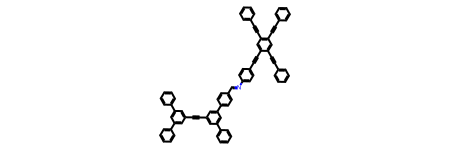

  分子拼接程序 - 最终版（边平行度判断）

[读取分子文件]
  ald: ald-result/ald-40.mol
  ami: ami-result/ami-19.mol

[计算两种构型的边平行度]
  -120°, 不翻转: 边平行度 = 0.8660, 偏离 = 0.1340
  -120°, 翻转: 边平行度 = 0.0000, 偏离 = 0.0000

  ✓ 选择: -120°, 翻转

[保存结果]
  MOL文件: ./dimer_ald-40_ami-19.mol
  结构图已保存: ./dimer_ald-40_ami-19.png

[结果统计]
  合并后原子数: 72
  合并后键数: 82
  剩余-CHO数量: 0
  剩余-NH2数量: 0
  分子式: C71H51N
  SMILES: Cc1c(-c2ccccc2)c(-c2ccccc2)c(C)c(-c2ccc(N=Cc3ccc(-c4cc(C#Cc5cc(-c6ccccc6)cc(-c6ccccc6)c5)cc(-c5ccccc5)c4)cc3)cc2)c1-c1ccccc1
完成!


[14:12:33] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[14:12:33] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[14:12:33] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.


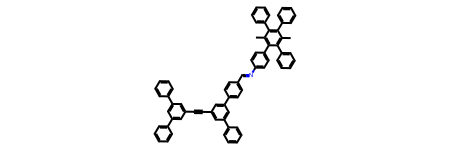

  分子拼接程序 - 最终版（边平行度判断）

[读取分子文件]
  ald: ald-result/ald-40.mol
  ami: ami-result/ami-18.mol

[计算两种构型的边平行度]
  -120°, 不翻转: 边平行度 = 0.8660, 偏离 = 0.1340
  -120°, 翻转: 边平行度 = 0.0000, 偏离 = 0.0000

  ✓ 选择: -120°, 翻转

[保存结果]
  MOL文件: ./dimer_ald-40_ami-18.mol
  结构图已保存: ./dimer_ald-40_ami-18.png

[结果统计]
  合并后原子数: 88
  合并后键数: 101
  剩余-CHO数量: 0
  剩余-NH2数量: 0
  分子式: C87H51N
  SMILES: C(#Cc1cc(C#Cc2ccccc2)c2ccc3c(C#Cc4ccc(N=Cc5ccc(-c6cc(C#Cc7cc(-c8ccccc8)cc(-c8ccccc8)c7)cc(-c7ccccc7)c6)cc5)cc4)cc(C#Cc4ccccc4)c4ccc1c2c43)c1ccccc1
完成!


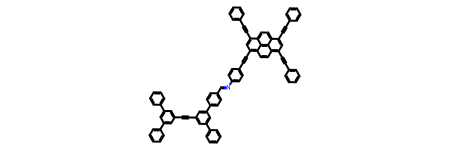

  分子拼接程序 - 最终版（边平行度判断）

[读取分子文件]
  ald: ald-result/ald-40.mol
  ami: ami-result/ami-16.mol

[计算两种构型的边平行度]
  -120°, 不翻转: 边平行度 = 0.8660, 偏离 = 0.1340
  -120°, 翻转: 边平行度 = 0.0000, 偏离 = 0.0000

  ✓ 选择: -120°, 翻转

[保存结果]
  MOL文件: ./dimer_ald-40_ami-16.mol
  结构图已保存: ./dimer_ald-40_ami-16.png

[结果统计]
  合并后原子数: 104
  合并后键数: 121
  剩余-CHO数量: 0
  剩余-NH2数量: 0
  分子式: C103H67N
  SMILES: C(#Cc1cc(-c2ccccc2)cc(-c2ccc(C=Nc3ccc(-c4ccc(-c5cc(-c6ccc(-c7ccccc7)cc6)c6ccc7c(-c8ccc(-c9ccccc9)cc8)cc(-c8ccc(-c9ccccc9)cc8)c8ccc5c6c78)cc4)cc3)cc2)c1)c1cc(-c2ccccc2)cc(-c2ccccc2)c1
完成!


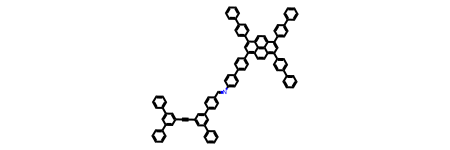

  分子拼接程序 - 最终版（边平行度判断）

[读取分子文件]
  ald: ald-result/ald-40.mol
  ami: ami-result/ami-15.mol

[计算两种构型的边平行度]
  -120°, 不翻转: 边平行度 = 0.5000, 偏离 = 0.5000
  -120°, 翻转: 边平行度 = 1.0000, 偏离 = 0.0000

  ✓ 选择: -120°, 翻转

[保存结果]
  MOL文件: ./dimer_ald-40_ami-15.mol
  结构图已保存: ./dimer_ald-40_ami-15.png

[结果统计]
  合并后原子数: 87
  合并后键数: 100
  剩余-CHO数量: 0
  剩余-NH2数量: 0
  分子式: C81H55N5S
  SMILES: C(#Cc1cc(-c2ccccc2)cc(-c2ccc(C=Nc3ccc(N(c4ccccc4)c4ccc(-c5ccc(-c6ccc(N(c7ccccc7)c7ccccc7)cc6)c6nsnc56)cc4)cc3)cc2)c1)c1cc(-c2ccccc2)cc(-c2ccccc2)c1
完成!


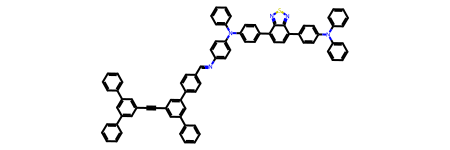